In [1]:
# 09_vlm_baseline.ipynb

# ============================ CELL 1: Setup ============================
from __future__ import annotations

import os
import json
import warnings
from pathlib import Path

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
os.environ["TRANSFORMERS_NO_ADVISORY_WARNINGS"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

# Disable tqdm globally
os.environ["TQDM_DISABLE"] = "1"

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from PIL import Image
from sklearn.metrics import (
    accuracy_score, classification_report, f1_score,
    precision_score, recall_score, roc_auc_score,
)
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from functools import partial

# =============================================================================
# Setup directories and device
# =============================================================================
OUTPUT_DIR = Path("./data/processed")
MODEL_DIR = Path("./models")
RESULT_DIR = Path("./results")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

IMG_SIZE = 224
torch.manual_seed(42)
np.random.seed(42)

# =============================================================================
# Import transformers (AFTER disabling progress bars)
# =============================================================================
try:
    from transformers import CLIPModel, CLIPProcessor
    from transformers.utils import logging as hf_logging
    hf_logging.set_verbosity_error()
    print("transformers library loaded successfully.")
except ImportError as e:
    raise ImportError(
        f"transformers not installed. Run: pip install transformers\nError: {e}"
    )


Device: cuda
transformers library loaded successfully.


In [2]:
# ==================== CELL 2: Load Data ====================
clinical_df = pd.read_csv(OUTPUT_DIR / "clinical_features_merged.csv")
frames_df = pd.read_csv(OUTPUT_DIR / "frames_index.csv")
original_df = pd.read_csv(OUTPUT_DIR / "clinical_features_original.csv")
frames_df["ID"] = frames_df["ID"].astype(str)

with open(OUTPUT_DIR / "splits.json") as f:
    splits = json.load(f)

train_df = clinical_df[clinical_df["ID"].isin(splits["train"])].reset_index(drop=True)
val_df = clinical_df[clinical_df["ID"].isin(splits["val"])].reset_index(drop=True)
test_df = clinical_df[clinical_df["ID"].isin(splits["test"])].reset_index(drop=True)

print(f"Train {len(train_df)} | Val {len(val_df)} | Test {len(test_df)}")

Train 255 | Val 46 | Test 76


In [3]:
# ==================== CELL 3: Dataset Classes ====================
class VLMTestDataset(Dataset):
    """Image + label only (for zero-shot evaluation)."""
    def __init__(self, patient_df, frames_df, transform=None):
        self.patients = patient_df.reset_index(drop=True)
        self.frames = frames_df
        self.transform = transform

    def __len__(self):
        return len(self.patients)

    def _load_image(self, pid):
        subset = self.frames[self.frames["ID"] == str(int(pid))]
        imgs = []
        for path in subset["path"].tolist():
            try:
                imgs.append(Image.open(path).convert("RGB"))
            except Exception:
                continue
        if not imgs:
            return Image.new("RGB", (IMG_SIZE, IMG_SIZE))
        return imgs[len(imgs) // 2]  # middle frame

    def __getitem__(self, idx):
        row = self.patients.iloc[idx]
        pid = int(row["ID"])
        img = self._load_image(pid)
        if self.transform:
            img = self.transform(img)
        label = torch.tensor(int(row["has_cad"]), dtype=torch.long)
        return img, label


class CLIPFineTuneDataset(Dataset):
    """Image + text prompt from tabular metadata."""
    def __init__(self, patient_df, frames_df, original_df):
        self.patients = patient_df.reset_index(drop=True)
        self.frames = frames_df
        self.original = original_df.set_index("ID")

    def __len__(self):
        return len(self.patients)

    def _load_image(self, pid):
        subset = self.frames[self.frames["ID"] == str(int(pid))]
        imgs = []
        for path in subset["path"].tolist():
            try:
                imgs.append(Image.open(path).convert("RGB"))
            except Exception:
                continue
        if not imgs:
            return Image.new("RGB", (IMG_SIZE, IMG_SIZE))
        return imgs[len(imgs) // 2]

    def _build_prompt(self, pid):
        row = self.original.loc[pid]
        age = int(row["Age"]) if not pd.isna(row["Age"]) else 60
        sex = str(row.get("Sex", "unknown")).lower()
        dm = "yes" if row.get("DM", 0) == 1 else "no"
        htn = "yes" if row.get("HTN", 0) == 1 else "no"
        smoker = "yes" if row.get("Current Smoker", 0) == 1 else "no"
        hlp = "yes" if row.get("Hyperlipidemia", 0) == 1 else "no"
        lvef = row.get("LVEF", None)
        lvef = int(lvef) if not pd.isna(lvef) else 55
        return (f"A coronary angiography of a {age}-year-old {sex} patient. "
                f"Diabetes: {dm}. Hypertension: {htn}. Smoker: {smoker}. "
                f"Hyperlipidemia: {hlp}. LVEF: {lvef} percent.")

    def __getitem__(self, idx):
        row = self.patients.iloc[idx]
        pid = int(row["ID"])
        image = self._load_image(pid)
        prompt = self._build_prompt(pid)
        label = torch.tensor(int(row["has_cad"]), dtype=torch.long)
        return image, prompt, label


In [4]:
# ==================== CELL 4: Load CLIP Model ====================
print("\n" + "=" * 60)
print("LOADING CLIP MODEL")
print("=" * 60)

MODEL_NAME = "openai/clip-vit-base-patch32"

# Load processor
clip_processor = CLIPProcessor.from_pretrained(MODEL_NAME)
print("Processor loaded.")

# Load model with suppressed warnings
clip_model = CLIPModel.from_pretrained(MODEL_NAME)
clip_model = clip_model.to(DEVICE)
clip_model.eval()
print("Model loaded and moved to device.")


LOADING CLIP MODEL


Processor loaded.
Model loaded and moved to device.


In [10]:
# ==================== CELL 5 ====================
print("PART 1: ZERO-SHOT CLIP (Fixed)")

# Better prompts that CLIP understands
class_prompts = [
    "a medical image of healthy heart arteries with no blockage",
    "a medical image of heart arteries with significant blockage or narrowing",
]

zs_tfms = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor()])
zs_test_ds = VLMTestDataset(test_df, frames_df, transform=zs_tfms)
zs_test_loader = DataLoader(zs_test_ds, batch_size=8, shuffle=False, num_workers=0)

y_true_zs, y_pred_zs, y_prob_zs = [], [], []

with torch.no_grad():
    for img_tensor, label in zs_test_loader:
        images_pil = [transforms.ToPILImage()(t) for t in img_tensor]

        inputs = clip_processor(
            text=class_prompts,
            images=images_pil,
            return_tensors="pt",
            padding=True,
            truncation=True,
        ).to(DEVICE)

        outputs = clip_model(**inputs)
        probs = outputs.logits_per_image.softmax(dim=1)

        y_true_zs.append(label.numpy())
        y_pred_zs.append(probs.argmax(dim=1).cpu().numpy())
        y_prob_zs.append(probs[:, 1].cpu().numpy())

y_true_zs = np.concatenate(y_true_zs)
y_pred_zs = np.concatenate(y_pred_zs)
y_prob_zs = np.concatenate(y_prob_zs)

# Debug: Check probability distribution
print(f"\nProbability stats (CAD class):")
print(f"  Mean: {y_prob_zs.mean():.4f}")
print(f"  Std:  {y_prob_zs.std():.4f}")
print(f"  Min:  {y_prob_zs.min():.4f}")
print(f"  Max:  {y_prob_zs.max():.4f}")
print(f"  Predicted CAD: {(y_pred_zs == 1).sum()} / {len(y_pred_zs)}")

# Use optimal threshold instead of 0.5
from sklearn.metrics import f1_score
best_thresh, best_f1 = 0.5, 0
for t in np.arange(0.1, 0.9, 0.05):
    preds = (y_prob_zs > t).astype(int)
    f1 = f1_score(y_true_zs, preds, zero_division=0)
    if f1 > best_f1:
        best_f1 = f1
        best_thresh = t

y_pred_zs = (y_prob_zs > best_thresh).astype(int)
print(f"\nOptimal threshold: {best_thresh:.2f}")

print("\nZero-Shot CLIP Results:")
print(classification_report(y_true_zs, y_pred_zs,
                            target_names=["No CAD", "CAD"], digits=4))

zs_metrics = {
    "accuracy": float(accuracy_score(y_true_zs, y_pred_zs)),
    "auc": float(roc_auc_score(y_true_zs, y_prob_zs)),
    "f1": float(f1_score(y_true_zs, y_pred_zs, zero_division=0)),
    "recall": float(recall_score(y_true_zs, y_pred_zs, zero_division=0)),
    "precision": float(precision_score(y_true_zs, y_pred_zs, zero_division=0)),
}
for k, v in zs_metrics.items():
    print(f"  {k:10s}: {v:.4f}")

PART 1: ZERO-SHOT CLIP (Fixed)

Probability stats (CAD class):
  Mean: 0.5737
  Std:  0.0701
  Min:  0.2920
  Max:  0.7080
  Predicted CAD: 68 / 76

Optimal threshold: 0.10

Zero-Shot CLIP Results:
              precision    recall  f1-score   support

      No CAD     0.0000    0.0000    0.0000        16
         CAD     0.7895    1.0000    0.8824        60

    accuracy                         0.7895        76
   macro avg     0.3947    0.5000    0.4412        76
weighted avg     0.6233    0.7895    0.6966        76

  accuracy  : 0.7895
  auc       : 0.6260
  f1        : 0.8824
  recall    : 1.0000
  precision : 0.7895


In [12]:
# ==================== CELL 6 (FIXED): Fine-Tune CLIP ====================
print("PART 2: FINE-TUNING CLIP")

# ---- Free zero-shot model from GPU ----
del clip_model
torch.cuda.empty_cache()
print("Freed zero-shot CLIP from GPU")


# ---- Focal Loss (consistent with Notebook 08) ----
class FocalLoss(nn.Module):
    def __init__(self, alpha=0.25, gamma=2.0, weight=None):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma
        if weight is not None:
            self.register_buffer("weight", weight)
        else:
            self.weight = None
    def forward(self, logits, targets):
        ce = nn.functional.cross_entropy(logits, targets,
                                         weight=self.weight, reduction="none")
        pt = torch.exp(-ce)
        return (self.alpha * (1.0 - pt) ** self.gamma * ce).mean()


# ---- Improved CLIP Classifier ----
class CLIPClassifier(nn.Module):
    """CLIP encoders + deeper fusion head."""
    def __init__(self, clip, num_classes=2):
        super().__init__()
        self.clip = clip

        # Freeze everything, unfreeze only projection layers
        for p in self.clip.parameters():
            p.requires_grad = False
        for p in self.clip.visual_projection.parameters():
            p.requires_grad = True
        for p in self.clip.text_projection.parameters():
            p.requires_grad = True

        d = clip.config.projection_dim
        # 🔧 IMPROVED: Deeper classifier with LayerNorm
        self.classifier = nn.Sequential(
            nn.Linear(d * 2, 512),
            nn.LayerNorm(512),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(512, 128),
            nn.LayerNorm(128),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes),
        )

    def forward(self, pixel_values, input_ids, attention_mask):
        out = self.clip(
            pixel_values=pixel_values,
            input_ids=input_ids,
            attention_mask=attention_mask,
        )
        fused = torch.cat([out.image_embeds, out.text_embeds], dim=1)
        return self.classifier(fused)


# ---- Create datasets ----
train_ft_ds = CLIPFineTuneDataset(train_df, frames_df, original_df)
val_ft_ds = CLIPFineTuneDataset(val_df, frames_df, original_df)
test_ft_ds = CLIPFineTuneDataset(test_df, frames_df, original_df)


# ---- Custom collate function ----
def clip_collate(batch, processor):
    images, prompts, labels = zip(*batch)
    inputs = processor(
        text=list(prompts),
        images=list(images),
        return_tensors="pt",
        padding=True,
        truncation=True,
    )
    return inputs, torch.stack(labels)


# ---- Create loaders ----
collate_fn = partial(clip_collate, processor=clip_processor)

train_loader_ft = DataLoader(train_ft_ds, batch_size=8, shuffle=True,
                              num_workers=0, collate_fn=collate_fn)
val_loader_ft = DataLoader(val_ft_ds, batch_size=8, shuffle=False,
                            num_workers=0, collate_fn=collate_fn)
test_loader_ft = DataLoader(test_ft_ds, batch_size=8, shuffle=False,
                             num_workers=0, collate_fn=collate_fn)


# ---- Fresh CLIP for fine-tuning ----
clip_ft_base = CLIPModel.from_pretrained(MODEL_NAME).to(DEVICE)
ft_model = CLIPClassifier(clip_ft_base).to(DEVICE)

# ---- Loss, optimizer, scheduler ----
weight_tensor = torch.tensor([2.406, 0.631], dtype=torch.float32).to(DEVICE)
criterion = FocalLoss(alpha=0.25, gamma=2.0, weight=weight_tensor)

EPOCHS = 15
PATIENCE = 5

# 🔧 IMPROVED: Lower LR + scheduler
optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, ft_model.parameters()),
    lr=5e-5,  # Was 1e-4
    weight_decay=1e-4,
)
scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=EPOCHS, eta_min=1e-6
)

# ---- Training loop ----
best_auc_ft, no_improve_ft = -1.0, 0
best_state_ft = None

print("\nStarting fine-tuning...")
for epoch in range(EPOCHS):
    # ---- Train ----
    ft_model.train()
    running_loss = 0.0

    for inputs, labels in train_loader_ft:
        pixel_values = inputs["pixel_values"].to(DEVICE)
        input_ids = inputs["input_ids"].to(DEVICE)
        attention_mask = inputs["attention_mask"].to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)
        logits = ft_model(pixel_values, input_ids, attention_mask)
        loss = criterion(logits, labels)
        loss.backward()

        # 🔧 IMPROVED: Gradient clipping for stability
        torch.nn.utils.clip_grad_norm_(ft_model.parameters(), max_norm=1.0)

        optimizer.step()
        running_loss += loss.item() * labels.size(0)

    scheduler.step()

    # ---- Validate ----
    ft_model.eval()
    v_preds, v_probs, v_labels = [], [], []

    with torch.no_grad():
        for inputs, labels in val_loader_ft:
            pixel_values = inputs["pixel_values"].to(DEVICE)
            input_ids = inputs["input_ids"].to(DEVICE)
            attention_mask = inputs["attention_mask"].to(DEVICE)

            logits = ft_model(pixel_values, input_ids, attention_mask)
            v_probs.append(torch.softmax(logits, dim=1)[:, 1].cpu().numpy())
            v_preds.append(logits.argmax(dim=1).cpu().numpy())
            v_labels.append(labels.numpy())

    y_vt = np.concatenate(v_labels)
    y_vp = np.concatenate(v_preds)
    y_vprob = np.concatenate(v_probs)
    val_auc = roc_auc_score(y_vt, y_vprob) if len(np.unique(y_vt)) > 1 else 0.5

    train_loss = running_loss / len(train_ft_ds)
    print(f"Epoch {epoch+1:02d} | Loss: {train_loss:.4f} | Val AUC: {val_auc:.4f}")

    if val_auc > best_auc_ft:
        best_auc_ft = val_auc
        no_improve_ft = 0
        best_state_ft = {k: v.clone() for k, v in ft_model.state_dict().items()}
    else:
        no_improve_ft += 1
        if no_improve_ft >= PATIENCE:
            print(f"Early stopping at epoch {epoch+1}")
            break

print(f"\nBest Val AUC: {best_auc_ft:.4f}")

PART 2: FINE-TUNING CLIP
Freed zero-shot CLIP from GPU

Starting fine-tuning...
Epoch 01 | Loss: 0.0784 | Val AUC: 0.6833
Epoch 02 | Loss: 0.0546 | Val AUC: 0.7500
Epoch 03 | Loss: 0.0584 | Val AUC: 0.7639
Epoch 04 | Loss: 0.0523 | Val AUC: 0.7667
Epoch 05 | Loss: 0.0514 | Val AUC: 0.7750
Epoch 06 | Loss: 0.0519 | Val AUC: 0.8056
Epoch 07 | Loss: 0.0492 | Val AUC: 0.8056
Epoch 08 | Loss: 0.0510 | Val AUC: 0.7944
Epoch 09 | Loss: 0.0480 | Val AUC: 0.7972
Epoch 10 | Loss: 0.0450 | Val AUC: 0.8028
Epoch 11 | Loss: 0.0453 | Val AUC: 0.8083
Epoch 12 | Loss: 0.0455 | Val AUC: 0.8083
Epoch 13 | Loss: 0.0439 | Val AUC: 0.8083
Epoch 14 | Loss: 0.0400 | Val AUC: 0.8083
Epoch 15 | Loss: 0.0419 | Val AUC: 0.8083

Best Val AUC: 0.8083


In [15]:
# ==================== CELL 7 (FIXED): Evaluate Fine-Tuned CLIP ====================
ft_model.load_state_dict(best_state_ft)
ft_model.eval()

test_preds_ft, test_probs_ft, test_labels_ft = [], [], []

with torch.no_grad():
    for inputs, labels in test_loader_ft:
        pixel_values = inputs["pixel_values"].to(DEVICE)
        input_ids = inputs["input_ids"].to(DEVICE)
        attention_mask = inputs["attention_mask"].to(DEVICE)

        logits = ft_model(pixel_values, input_ids, attention_mask)
        test_probs_ft.append(torch.softmax(logits, dim=1)[:, 1].cpu().numpy())
        test_preds_ft.append(logits.argmax(dim=1).cpu().numpy())
        test_labels_ft.append(labels.numpy())

y_true_ft = np.concatenate(test_labels_ft)
y_pred_ft = np.concatenate(test_preds_ft)
y_prob_ft = np.concatenate(test_probs_ft)

# =============================================================================
# 🔧 FIX: Debug probability distribution first
# =============================================================================
print("\n" + "=" * 60)
print("FINE-TUNED CLIP — Probability Stats")
print("=" * 60)
print(f"  Mean:  {y_prob_ft.mean():.4f}")
print(f"  Std:   {y_prob_ft.std():.4f}")
print(f"  Min:   {y_prob_ft.min():.4f}")
print(f"  Max:   {y_prob_ft.max():.4f}")
print(f"  Median: {np.median(y_prob_ft):.4f}")
print(f"  Predicted CAD (threshold=0.5): {(y_pred_ft == 1).sum()} / {len(y_pred_ft)}")

# =============================================================================
# 🔧 FIX: Threshold tuning — find optimal threshold for F1
# =============================================================================
from sklearn.metrics import f1_score

best_thresh_ft, best_f1_ft = 0.5, 0
threshold_results = []

print("\nThreshold tuning:")
print(f"{'Threshold':<12} {'F1':<10} {'Recall':<10} {'Precision':<10}")
print("-" * 45)

for t in np.arange(0.05, 0.95, 0.05):
    preds_t = (y_prob_ft > t).astype(int)
    f1_t = f1_score(y_true_ft, preds_t, zero_division=0)
    rec_t = recall_score(y_true_ft, preds_t, zero_division=0)
    prec_t = precision_score(y_true_ft, preds_t, zero_division=0)

    threshold_results.append({
        "threshold": round(t, 2),
        "F1": f1_t,
        "Recall": rec_t,
        "Precision": prec_t,
    })

    print(f"{t:<12.2f} {f1_t:<10.4f} {rec_t:<10.4f} {prec_t:<10.4f}")

    if f1_t > best_f1_ft:
        best_f1_ft = f1_t
        best_thresh_ft = t

print(f"\n🎯 Optimal threshold: {best_thresh_ft:.2f}")
print(f"🎯 Best F1 at threshold: {best_f1_ft:.4f}")

# =============================================================================
# 🔧 FIX: Apply optimal threshold
# =============================================================================
y_pred_ft = (y_prob_ft > best_thresh_ft).astype(int)

print("\n" + "=" * 60)
print(f"FINE-TUNED CLIP — Classification Report @ threshold={best_thresh_ft:.2f}")
print("=" * 60)
print(classification_report(y_true_ft, y_pred_ft,
                            target_names=["No CAD", "CAD"], digits=4))

# =============================================================================
# Compute final metrics
# =============================================================================
ft_metrics = {
    "accuracy": float(accuracy_score(y_true_ft, y_pred_ft)),
    "auc": float(roc_auc_score(y_true_ft, y_prob_ft)),
    "f1": float(f1_score(y_true_ft, y_pred_ft, zero_division=0)),
    "recall": float(recall_score(y_true_ft, y_pred_ft, zero_division=0)),
    "precision": float(precision_score(y_true_ft, y_pred_ft, zero_division=0)),
    "optimal_threshold": float(best_thresh_ft),
}

print("\nFinal Metrics:")
for k, v in ft_metrics.items():
    if k == "optimal_threshold":
        print(f"  {k:20s}: {v:.2f}")
    else:
        print(f"  {k:20s}: {v:.4f}")

# =============================================================================
# Also report with default threshold (0.5) for comparison
# =============================================================================
print("\n" + "-" * 60)
print("Comparison: Default (0.5) vs Optimal threshold")
print("-" * 60)

y_pred_default = (y_prob_ft > 0.5).astype(int)

default_metrics = {
    "F1": f1_score(y_true_ft, y_pred_default, zero_division=0),
    "Recall": recall_score(y_true_ft, y_pred_default, zero_division=0),
    "Precision": precision_score(y_true_ft, y_pred_default, zero_division=0),
    "Accuracy": accuracy_score(y_true_ft, y_pred_default),
}

optimal_metrics = {
    "F1": ft_metrics["f1"],
    "Recall": ft_metrics["recall"],
    "Precision": ft_metrics["precision"],
    "Accuracy": ft_metrics["accuracy"],
}

print(f"{'Metric':<12} {'Default(0.5)':<15} {'Optimal':<15} {'Change':<10}")
print("-" * 52)
for k in ["F1", "Recall", "Precision", "Accuracy"]:
    change = optimal_metrics[k] - default_metrics[k]
    print(f"{k:<12} {default_metrics[k]:<15.4f} {optimal_metrics[k]:<15.4f} {change:+.4f}")


FINE-TUNED CLIP — Probability Stats
  Mean:  0.4446
  Std:   0.0829
  Min:   0.2375
  Max:   0.5915
  Median: 0.4474
  Predicted CAD (threshold=0.5): 18 / 76

Threshold tuning:
Threshold    F1         Recall     Precision 
---------------------------------------------
0.05         0.8824     1.0000     0.7895    
0.10         0.8824     1.0000     0.7895    
0.15         0.8824     1.0000     0.7895    
0.20         0.8824     1.0000     0.7895    
0.25         0.8889     1.0000     0.8000    
0.30         0.8722     0.9667     0.7945    
0.35         0.8871     0.9167     0.8594    
0.40         0.8621     0.8333     0.8929    
0.45         0.6804     0.5500     0.8919    
0.50         0.4615     0.3000     1.0000    
0.55         0.2857     0.1667     1.0000    
0.60         0.0000     0.0000     0.0000    
0.65         0.0000     0.0000     0.0000    
0.70         0.0000     0.0000     0.0000    
0.75         0.0000     0.0000     0.0000    
0.80         0.0000     0.0000     0.000

In [16]:
# ==================== CELL 8: Save Results ====================
vlm_results = pd.DataFrame([
    {"Model": "CLIP Zero-Shot", **zs_metrics},
    {"Model": "CLIP Fine-Tuned", **ft_metrics},
])

vlm_results.to_csv(RESULT_DIR / "vlm_results.csv", index=False)

print("\n" + "=" * 60)
print("VLM RESULTS SUMMARY")
print("=" * 60)
print(vlm_results.round(4).to_string(index=False))



VLM RESULTS SUMMARY
          Model  accuracy    auc     f1  recall  precision  optimal_threshold
 CLIP Zero-Shot    0.7895 0.6260 0.8824     1.0     0.7895                NaN
CLIP Fine-Tuned    0.8026 0.7844 0.8889     1.0     0.8000               0.25


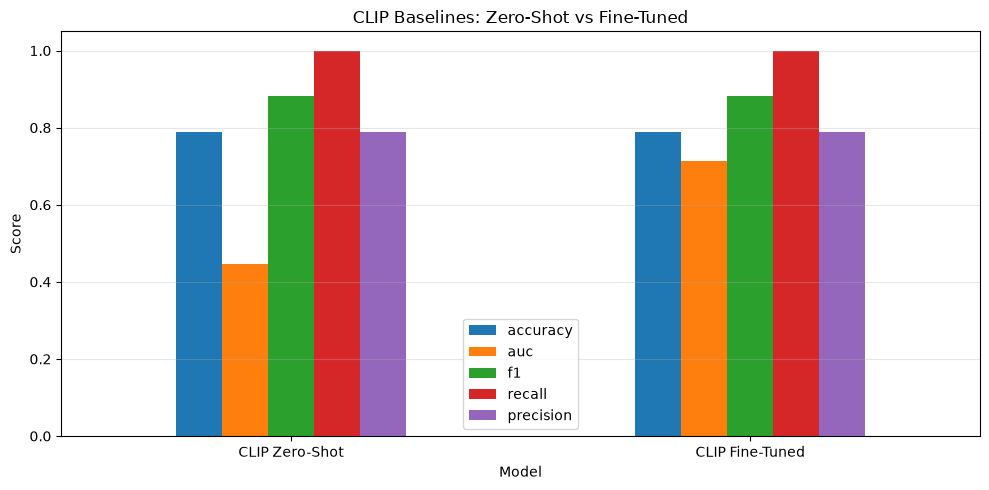


✅ Saved to results\vlm_results.csv


In [9]:
# ==================== CELL 9: Comparison Plot ====================
fig, ax = plt.subplots(figsize=(10, 5))
vlm_results.set_index("Model")[
    ["accuracy", "auc", "f1", "recall", "precision"]
].plot(kind="bar", ax=ax, rot=0)
ax.set_title("CLIP Baselines: Zero-Shot vs Fine-Tuned")
ax.set_ylabel("Score")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(RESULT_DIR / "vlm_comparison.png", dpi=200)
plt.show()

print(f"\n✅ Saved to {RESULT_DIR / 'vlm_results.csv'}")